In [2]:
import matplotlib.pyplot as plt
import numpy as np
import keras
from keras import layers
from keras.datasets import california_housing

(inputs, targets), (x_test, y_test) = california_housing.load_data(version='large', test_split=0.2)

print(inputs.shape, targets.shape)
print(x_test.shape, y_test.shape)

(16512, 8) (16512,)
(4128, 8) (4128,)


In [3]:
#0.8*16512 ≈ 13200
x_train = inputs[:13200]
y_train = targets[:13200]
x_val = inputs[13200:]
y_val = targets[13200:]

mean = x_train.mean(axis=0) # mean and standard deviation computed from training set only 
std = x_train.std(axis=0)
x_train -= mean
x_train /= std
x_test -= mean
x_test /= std
x_val -= mean
x_val /= std
y_train /= 1e5
y_test /= 1e5
y_val /= 1e5

In [6]:
inputs = keras.Input(shape=(8,))
x = layers.Dense(64, activation='relu')(inputs)
x = layers.Dense(64, activation='relu')(x)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(optimizer='adam',loss='mse',metrics=['mae'])

history = model.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)

E0000 00:00:1793355863.847511   21486 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


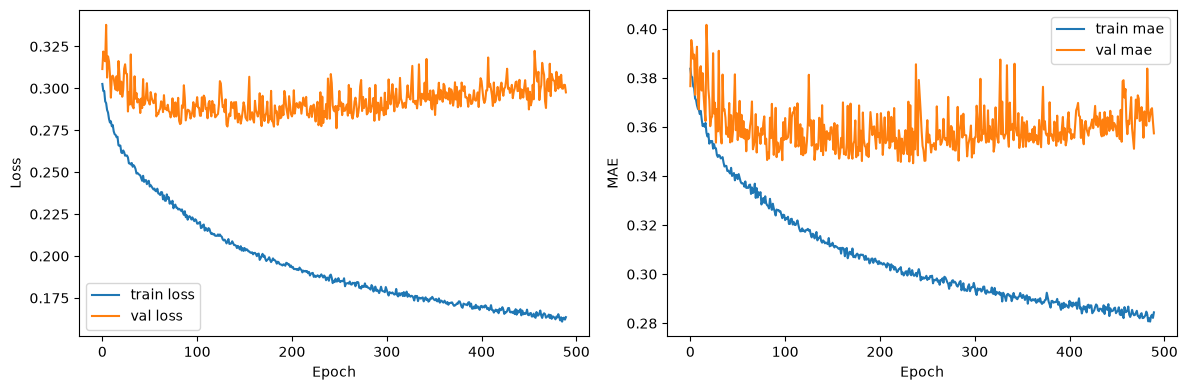

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'][10:], label='train loss')
plt.plot(history.history['val_loss'][10:], label='val loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'][10:], label='train mae')
plt.plot(history.history['val_mae'][10:], label='val mae')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('MAE')

plt.tight_layout()
plt.show()

In [10]:
inputs = keras.Input(shape=(8,))
x = layers.Dense(64, activation='relu')(inputs)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(1)(x)

model = keras.Model(inputs=inputs, outputs=outputs)

model.compile(optimizer='adam',loss='mse',metrics=['mae'])

history = model.fit(x_train, y_train, epochs=500, batch_size=32, validation_data=(x_val, y_val), verbose=0)

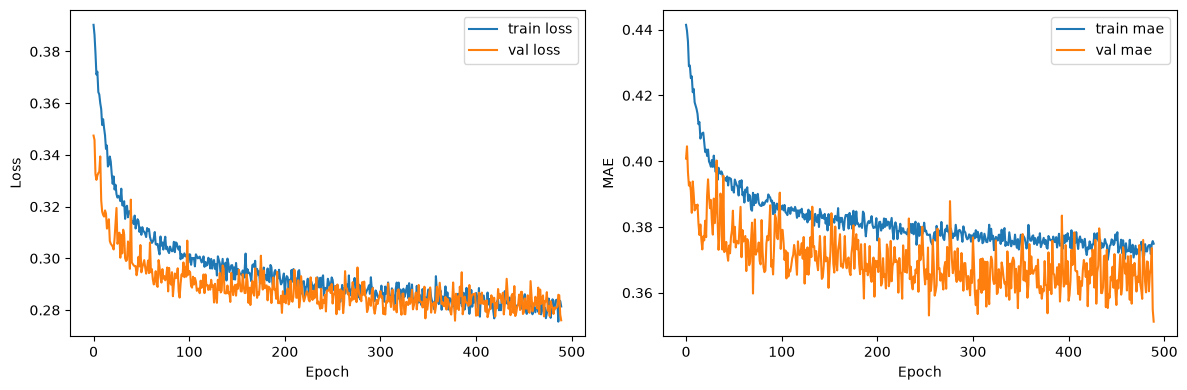

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'][10:], label='train loss')
plt.plot(history.history['val_loss'][10:], label='val loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.subplot(1, 2, 2)
plt.plot(history.history['mae'][10:], label='train mae')
plt.plot(history.history['val_mae'][10:], label='val mae')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('MAE')

plt.tight_layout()
plt.show()